# Preprocessing: BPE tokenization

Dataset: `cardiffnlp/tweet_eval` (emotion). Exact duplicate training texts are removed before fitting the tokenizer; validation and test remain unchanged. Identical texts with conflicting labels raise an error instead of being silently discarded.

Preprocessing is kept minimal: punctuation is kept, and there is no stopword removal, stemming or lemmatisation (tweets are short, noisy and full of misspellings). We compare BPE tokenizers over a grid of hyperparameters:
- **`lowercase`** or keep the original case (capitals can signal intensity);
- **`vocab_size`**: number of tokens in the vocabulary;
- **`min_frequency`**: a pair of tokens is only merged if it appears at least this many times;
- **`pre-tokenizer`**: `Metaspace` (tutorial default) splits only on blanks and marks each word start with `▁`, so `sad!!` becomes the chunk `▁sad!!`. `Whitespace` also splits punctuation (`sad`, `!!`) but drops the blanks.

The tokenizer is trained with `part1.experiment.train_tokenizer` from the tutorial.

In [1]:
import sys
from pathlib import Path

# Assuming the working directory is root/part1
sys.path.insert(0, str(Path.cwd().parent))

import part1
from datasets import load_dataset

dataset = load_dataset("cardiffnlp/tweet_eval", "emotion")
seen = {}
unique_indices = []
for i, example in enumerate(dataset["train"]):
    text, label = example["text"], example["label"]
    if text in seen:
        if seen[text] != label:
            raise ValueError(f"Duplicate training text has conflicting labels at row {i}.")
    else:
        seen[text] = label
        unique_indices.append(i)
removed = len(dataset["train"]) - len(unique_indices)
dataset["train"] = dataset["train"].select(unique_indices)
print(f"Removed {removed} duplicate training examples; {len(dataset['train'])} remain.")
emotion_outcome_space = part1.clslib.NamedClasses(dataset["train"].features["label"].names)
example_tweet = dataset["train"][0]["text"]

print(dataset)
print(emotion_outcome_space)
print("Original:", example_tweet)

Removed 25 duplicate training examples; 3232 remain.
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3232
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
})
0: anger, 1: joy, 2: optimism, 3: sadness
Original: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry


## BPE tokenizer

The tokenizer is trained only on the training split.

In [2]:
from tokenizers.pre_tokenizers import Metaspace, Whitespace

PRETOKENIZERS = {"metaspace": Metaspace, "whitespace": Whitespace}


class BPEPreprocessor:
    """Optional lowercasing + BPE tokenization.

    Call `fit(train_texts)` first, then `tokenize(text)` returns the BPE tokens.
    """

    def __init__(self, lowercase=True, vocab_size=5000, min_frequency=2, pretokenizer="metaspace"):
        self.lowercase = lowercase
        self.vocab_size = vocab_size
        self.min_frequency = min_frequency
        self.pretokenizer = pretokenizer
        self.tokenizer = None

    def fit(self, train_texts):
        corpus = [t.lower() for t in train_texts] if self.lowercase else list(train_texts)
        self.tokenizer = part1.experiment.train_tokenizer(
            corpus, self.vocab_size, self.min_frequency, pretokenizer=PRETOKENIZERS[self.pretokenizer]()
        )
        return self

    def tokenize(self, text):
        return self.tokenizer.encode(text.lower() if self.lowercase else text).tokens

    def __len__(self):
        """Number of tokens in the learned vocabulary."""
        return self.tokenizer.get_vocab_size()

## Hyperparameter grid

Every combination below is trained on the training split only.

In [3]:
import itertools
from tqdm.auto import tqdm

GRID = {
    "lowercase": [True, False],
    "vocab_size": [500, 1000, 2000],
    "min_frequency": [2, 5],
    "pretokenizer": ["metaspace", "whitespace"],
}
configs = [dict(zip(GRID, values)) for values in itertools.product(*GRID.values())]
print(len(configs), "configurations")

train_texts = dataset["train"]["text"]
preprocessors = [BPEPreprocessor(**cfg).fit(train_texts) for cfg in tqdm(configs)]

print("Original:", example_tweet)
for cfg, prep in zip(configs, preprocessors):
    print(cfg, "->", prep.tokenize(example_tweet))


def find(**wanted):
    """Return the fitted preprocessor matching the given hyperparameters."""
    return next(p for c, p in zip(configs, preprocessors) if all(c[k] == v for k, v in wanted.items()))

24 configurations


  0%|          | 0/24 [00:00<?, ?it/s]









































































Original: “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'metaspace'} -> ['▁', '“', 'w', 'or', 'ry', '▁is', '▁a', '▁d', 'ow', 'n', '▁p', 'ay', 'm', 'ent', '▁on', '▁a', '▁p', 'ro', 'ble', 'm', '▁you', '▁m', 'ay', '▁ne', 'ver', '▁have', "'", '.', '▁', '\xa0', 'j', 'o', 'y', 'ce', '▁me', 'y', 'er', '.', '▁', '▁#', 'm', 'ot', 'i', 'v', 'at', 'ion', '▁#', 'le', 'ad', 'ers', 'h', 'i', 'p', '▁#', 'w', 'or', 'ry']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'whitespace'} -> ['“', 'wor', 'ry', 'is', 'a', 'do', 'wn', 'p', 'ay', 'm', 'ent', 'on', 'a', 'pro', 'ble', 'm', 'you', 'm', 'ay', 'ne', 'ver', 'have', "'", '.', 'jo', 'y', 'ce', 'me', 'y', 'er', '.', '#', 'mo', 'ti', 'v', 'ation', '#', 'le', 'ad', 'ers', 'hi', 'p', '#', 'wor', 'ry']
{'lowercase': True, 'vocab

## Inspecting every vocabulary

- **longest tokens**: whole words, hashtags or emojis it managed to keep in one piece;
- **first learned tokens**: ids right after the initial alphabet are the earliest (most frequent) merges;
- **tokens with symbols**: how punctuation and hashtags are handled.

In [4]:
import statistics

clean = lambda t: t.lstrip("\u2581")  # drop the Metaspace marker when measuring length

for cfg, prep in zip(configs, preprocessors):
    vocab = prep.tokenizer.get_vocab()  # token -> id
    by_id = sorted(vocab, key=vocab.get)

    print("=" * 100)
    print(cfg)
    lengths = [len(clean(t)) for t in vocab]
    print(f"token length: mean={statistics.mean(lengths):.2f}  median={statistics.median(lengths)}  max={max(lengths)}")
    print("longest tokens:", sorted(vocab, key=lambda t: -len(clean(t)))[:25])
    print("tokens with symbols:", [t for t in by_id if len(clean(t)) > 1 and not clean(t).replace("'", "").isalnum()][:30])

{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'metaspace'}
token length: mean=1.54  median=1.0  max=5
longest tokens: ['[UNK]', "▁don't", '▁about', '▁@user', '▁what', '▁have', '▁like', "▁it's", 'king', '▁they', 'ress', '▁with', '▁this', '▁some', 'user', 'ould', '▁when', 'ally', '▁your', '▁that', 'ight', '▁just', 'ere', "▁i'm", '▁wor']
tokens with symbols: ['[UNK]', '▁@user', '..', '▁#s', '\\n', '!!', '...', '▁#b', '▁#h', '▁#f', '▁#d']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 2, 'pretokenizer': 'whitespace'}
token length: mean=1.67  median=1.0  max=6
longest tokens: ['people', 'thing', '[UNK]', 'press', 'ation', 'about', 'cking', 'will', 'when', 'ight', 'ther', 'what', 'king', 'ally', 'that', 'from', 'ting', 'they', 'user', 'ever', 'have', 'with', 'like', 'than', 'your']
tokens with symbols: ['[UNK]', '..', '!!', '...']
{'lowercase': True, 'vocab_size': 500, 'min_frequency': 5, 'pretokenizer': 'metaspace'}
token length: mean=1.54  median=1.0  

## Default tokenizer

Shared configuration to start from: lowercase, `Whitespace` pre-tokenizer, 2000 tokens, `min_frequency=2`. Use `default_prep` to tokenize new text, and `preprocessed` (train/validation/test) for the already tokenized dataset with its labels.

In [5]:
default_prep = BPEPreprocessor(lowercase=True, vocab_size=2000, min_frequency=2, pretokenizer="whitespace").fit(train_texts)

# Whole dataset, preprocessed: tokens and labels per split (same fitted tokenizer for all splits)
preprocessed = {
    split: {
        "tokens": [default_prep.tokenize(t) for t in dataset[split]["text"]],
        "labels": dataset[split]["label"],
    }
    for split in dataset
}
print({split: len(d["tokens"]) for split, d in preprocessed.items()})
print(preprocessed["train"]["tokens"][0], preprocessed["train"]["labels"][0])




{'train': 3232, 'test': 1421, 'validation': 374}
['“', 'worry', 'is', 'a', 'down', 'pay', 'ment', 'on', 'a', 'problem', 'you', 'may', 'never', 'have', "'", '.', 'joy', 'ce', 'me', 'y', 'er', '.', '#', 'motiv', 'ation', '#', 'leaders', 'hip', '#', 'worry'] 2


## Token indicator encoder

`BPETokenIndicator` maps a list of preprocessed BPE tokens to a binary vector with one dimension per vocabulary token. For a new text, call `default_prep.tokenize(text)` before passing the tokens to the encoder.

In [6]:
import numpy as np


class BPETokenIndicator(part1.clslib.Encoder):
    """Encode preprocessed BPE tokens as a binary indicator vector."""

    def __init__(self, prep):
        self.prep = prep
        self.vocab = prep.tokenizer.get_vocab()

    def __len__(self):
        return self.prep.tokenizer.get_vocab_size()

    def __call__(self, tokens):
        if isinstance(tokens, str):
            raise TypeError("Expected preprocessed tokens, not raw text; tokenize the text first.")
        ids = [self.vocab[token] for token in set(tokens)]
        vector = np.zeros(len(self))
        vector[ids] = 1
        return vector


encoder = BPETokenIndicator(default_prep)
h = encoder(preprocessed["train"]["tokens"][0])
id_to_token = {i: t for t, i in default_prep.tokenizer.get_vocab().items()}
print("dimensions:", len(encoder), "| active:", int(h.sum()))
print(sorted(id_to_token[i] for i in np.flatnonzero(h)))

dimensions: 2000 | active: 25
['#', "'", '.', 'a', 'ation', 'ce', 'down', 'er', 'have', 'hip', 'is', 'joy', 'leaders', 'may', 'me', 'ment', 'motiv', 'never', 'on', 'pay', 'problem', 'worry', 'y', 'you', '“']


## Sparse MLP and cross-validation

Train a sparse MLP with two hidden layers for 20 epochs using cross-validation. `MLPClassifier.fit` uses the tutorial's progress bar and NLL loss, and saves the best model by macro-F1; `MLPClassifier.load` loads it. Existing cell outputs may be from an earlier run; rerun the cells to update them.

In [7]:
import json
import torch
import torch.nn as nn
from scipy.sparse import csr_matrix
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from part1.smlp import SparseMLP, SparseDataset, sparse_collate, train_one_epoch, evaluate


class MLPClassifier(SparseMLP):
    """Tutorial MLP with one additional hidden layer."""

    def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.1):
        super().__init__(input_dim, hidden_dim, num_classes, dropout)
        self.model_args = {"input_dim": input_dim, "hidden_dim": hidden_dim,
                           "num_classes": num_classes, "dropout": dropout}
        self.output = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes), nn.LogSoftmax(dim=-1)
        )

    def fit(self, train_X, train_y, val_X, val_y, save_to, batch_size=64,
            learning_rate=1e-4, weight_decay=1e-4, num_epochs=20, device="cpu"):
        """Train with NLL loss and keep the best validation macro-F1 model."""
        if num_epochs < 1:
            raise ValueError("num_epochs must be at least 1")
        train_loader = DataLoader(SparseDataset(train_X, train_y), batch_size=batch_size,
                                  shuffle=True, collate_fn=sparse_collate)
        val_loader = DataLoader(SparseDataset(val_X, val_y), batch_size=batch_size,
                                shuffle=False, collate_fn=sparse_collate)

        with open(f"{save_to}.json", "w", encoding="utf-8") as f:
            json.dump(self.model_args, f, indent=2)
        self.to(device)
        criterion = nn.NLLLoss()
        optimizer = torch.optim.AdamW(self.parameters(), lr=learning_rate, weight_decay=weight_decay)

        best_loss = float("inf")
        print("Training...")
        for epoch in tqdm(range(num_epochs)):
            train_metrics = train_one_epoch(self, train_loader, optimizer, criterion, device)
            val_metrics, preds = evaluate(self, val_loader, criterion, device)
            val_f1 = f1_score(val_y, preds, labels=range(self.model_args["num_classes"]),
                              average="macro", zero_division=0)
            print(f"Epoch {epoch + 1:02d} | train loss: {train_metrics['loss']:.4f} | "
                  f"val loss: {val_metrics['loss']:.4f} | val macro-F1: {val_f1:.4f}")
            if val_metrics["loss"] <= best_loss:
                best_loss = val_metrics["loss"]
                best_epoch, predictions = epoch, preds
                torch.save(self.state_dict(), f"{save_to}.pt")
        self.load_state_dict(torch.load(f"{save_to}.pt", map_location=device, weights_only=True))
        return best_epoch, best_loss, predictions

    @classmethod
    def load(cls, path):
        with open(f"{path}.json", encoding="utf-8") as f:
            model = cls(**json.load(f))
        model.load_state_dict(torch.load(f"{path}.pt", map_location="cpu", weights_only=True))
        return model

In [8]:
from pathlib import Path

train_X = csr_matrix([encoder(tokens) for tokens in preprocessed["train"]["tokens"]])
train_y = np.asarray(preprocessed["train"]["labels"], dtype=int)
train_pairs = list(zip(preprocessed["train"]["tokens"], train_y))
print(f"Training indicators: {train_X.shape}, nonzero entries: {train_X.nnz}")

seed = 0
num_folds = 5
folds = part1.experiment.cross_validation_split(train_pairs, k=num_folds, seed=seed)

# One additional hidden layer and a higher learning rate than the tutorial.
model_args = {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
              "learning_rate": 3e-4, "weight_decay": 1e-4, "num_epochs": 20}
model_name = "mlp-two-layers"
results_folder = Path(part1.__file__).resolve().parent.parent / "results" / "mlp_bpe_macro_f1" / "deduplicated-lr-1e-4-20-epochs"
model_folder = results_folder / model_name / f"seed-{seed}"

Training indicators: (3232, 2000), nonzero entries: 78669


In [9]:
results_folder.mkdir(parents=True, exist_ok=True)
encoder.prep.tokenizer.save(str(results_folder / "tokenizer.json"))
with open(results_folder / "preprocessor.json", "w", encoding="utf-8") as f:
    json.dump({"lowercase": encoder.prep.lowercase, "vocab_size": encoder.prep.vocab_size,
               "min_frequency": encoder.prep.min_frequency, "pretokenizer": encoder.prep.pretokenizer}, f)

for fold, split in folds.items():
    print(f"\n{model_name} | seed {seed} | fold {fold + 1}/{num_folds}")
    fold_folder = model_folder / f"fold-{fold}"
    fold_folder.mkdir(parents=True, exist_ok=True)

    train_ids = np.asarray(split["training_ids"], dtype=int)
    val_ids = np.asarray(split["validation_ids"], dtype=int)
    torch.manual_seed(seed)
    model = MLPClassifier(train_X.shape[1], model_args["hidden_dim"],
                          len(emotion_outcome_space), model_args["dropout"])
    best_epoch, best_f1, _ = model.fit(
        train_X[train_ids], train_y[train_ids], train_X[val_ids], train_y[val_ids],
        save_to=str(fold_folder / "model"), batch_size=model_args["batch_size"],
        learning_rate=model_args["learning_rate"], weight_decay=model_args["weight_decay"],
        num_epochs=model_args["num_epochs"]
    )
    with open(fold_folder / "metrics.json", "w", encoding="utf-8") as f:
        json.dump({"model_args": model_args, "best_epoch": best_epoch,
                   "macro_f1": best_f1}, f, indent=2)


mlp-two-layers | seed 0 | fold 1/5
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/teodorasocola/Documents/University/MSc Artificial Intelligence (UvA) (2026 - 2028)/Year 1 (31 August 2026 - 25 July 2027)/Semester 1 (31 August 2026 - 29 January 2027)/Period 2 (26 October - 18 December 2026)/Natural Language Processing 1 (52041NLP6Y)/Assignments/nlp_first_assignment/part1/smlp.py:71: UserWarning: Sparse invariant c

Epoch 01 | train loss: 1.3414 | val loss: 1.2943 | val macro-F1: 0.1488
Epoch 02 | train loss: 1.2402 | val loss: 1.2487 | val macro-F1: 0.1488
Epoch 03 | train loss: 1.1759 | val loss: 1.2039 | val macro-F1: 0.1673
Epoch 04 | train loss: 1.0695 | val loss: 1.1243 | val macro-F1: 0.2771
Epoch 05 | train loss: 0.8955 | val loss: 1.0203 | val macro-F1: 0.4135
Epoch 06 | train loss: 0.6952 | val loss: 0.9271 | val macro-F1: 0.4794
Epoch 07 | train loss: 0.5139 | val loss: 0.8888 | val macro-F1: 0.5322
Epoch 08 | train loss: 0.3791 | val loss: 0.8777 | val macro-F1: 0.5589
Epoch 09 | train loss: 0.2864 | val loss: 0.8920 | val macro-F1: 0.5691
Epoch 10 | train loss: 0.2161 | val loss: 0.9041 | val macro-F1: 0.6066
Epoch 11 | train loss: 0.1632 | val loss: 0.9208 | val macro-F1: 0.6038
Epoch 12 | train loss: 0.1264 | val loss: 0.9681 | val macro-F1: 0.6177
Epoch 13 | train loss: 0.1037 | val loss: 0.9960 | val macro-F1: 0.6054
Epoch 14 | train loss: 0.0831 | val loss: 1.0424 | val macro-F1:

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3430 | val loss: 1.2826 | val macro-F1: 0.1522
Epoch 02 | train loss: 1.2455 | val loss: 1.2255 | val macro-F1: 0.1522
Epoch 03 | train loss: 1.1839 | val loss: 1.1754 | val macro-F1: 0.1669
Epoch 04 | train loss: 1.0765 | val loss: 1.0876 | val macro-F1: 0.2740
Epoch 05 | train loss: 0.9021 | val loss: 0.9735 | val macro-F1: 0.4633
Epoch 06 | train loss: 0.6967 | val loss: 0.8836 | val macro-F1: 0.5029
Epoch 07 | train loss: 0.5150 | val loss: 0.8639 | val macro-F1: 0.5921
Epoch 08 | train loss: 0.3771 | val loss: 0.8537 | val macro-F1: 0.6311
Epoch 09 | train loss: 0.2834 | val loss: 0.8655 | val macro-F1: 0.6403
Epoch 10 | train loss: 0.2146 | val loss: 0.9003 | val macro-F1: 0.6360
Epoch 11 | train loss: 0.1608 | val loss: 0.9469 | val macro-F1: 0.6330
Epoch 12 | train loss: 0.1208 | val loss: 1.0135 | val macro-F1: 0.6411
Epoch 13 | train loss: 0.0994 | val loss: 1.0419 | val macro-F1: 0.6267
Epoch 14 | train loss: 0.0804 | val loss: 1.0911 | val macro-F1:

... (2 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3426 | val loss: 1.2831 | val macro-F1: 0.1538
Epoch 02 | train loss: 1.2445 | val loss: 1.2265 | val macro-F1: 0.1538
Epoch 03 | train loss: 1.1815 | val loss: 1.1826 | val macro-F1: 0.1686
Epoch 04 | train loss: 1.0753 | val loss: 1.1026 | val macro-F1: 0.2947
Epoch 05 | train loss: 0.8947 | val loss: 1.0110 | val macro-F1: 0.4253
Epoch 06 | train loss: 0.6857 | val loss: 0.9335 | val macro-F1: 0.4867
Epoch 07 | train loss: 0.5057 | val loss: 0.8947 | val macro-F1: 0.5525
Epoch 08 | train loss: 0.3731 | val loss: 0.8973 | val macro-F1: 0.5777
Epoch 09 | train loss: 0.2763 | val loss: 0.9182 | val macro-F1: 0.5678
Epoch 10 | train loss: 0.2061 | val loss: 0.9640 | val macro-F1: 0.5752
Epoch 11 | train loss: 0.1552 | val loss: 1.0057 | val macro-F1: 0.5834
Epoch 12 | train loss: 0.1209 | val loss: 1.0377 | val macro-F1: 0.6009
Epoch 13 | train loss: 0.0958 | val loss: 1.0808 | val macro-F1: 0.5846
Epoch 14 | train loss: 0.0785 | val loss: 1.1390 | val macro-F1:

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3448 | val loss: 1.2790 | val macro-F1: 0.1531
Epoch 02 | train loss: 1.2500 | val loss: 1.2155 | val macro-F1: 0.1531
Epoch 03 | train loss: 1.1847 | val loss: 1.1711 | val macro-F1: 0.1592
Epoch 04 | train loss: 1.0779 | val loss: 1.0861 | val macro-F1: 0.3088
Epoch 05 | train loss: 0.8964 | val loss: 0.9764 | val macro-F1: 0.4271
Epoch 06 | train loss: 0.6877 | val loss: 0.9004 | val macro-F1: 0.5083
Epoch 07 | train loss: 0.5047 | val loss: 0.8684 | val macro-F1: 0.5761
Epoch 08 | train loss: 0.3762 | val loss: 0.8785 | val macro-F1: 0.5847
Epoch 09 | train loss: 0.2771 | val loss: 0.8994 | val macro-F1: 0.5831
Epoch 10 | train loss: 0.2105 | val loss: 0.9412 | val macro-F1: 0.5933
Epoch 11 | train loss: 0.1593 | val loss: 0.9692 | val macro-F1: 0.6030
Epoch 12 | train loss: 0.1237 | val loss: 1.0132 | val macro-F1: 0.6037
Epoch 13 | train loss: 0.0964 | val loss: 1.0516 | val macro-F1: 0.6064
Epoch 14 | train loss: 0.0803 | val loss: 1.1123 | val macro-F1:

### Cross-validation results

The box and points show the best validation macro-F1 across the 20 epochs for each fold. Run the setup cells and this cell to read saved results without retraining.

                    mean       std  count
model                                    
mlp-two-layers  0.890898  0.041388      5


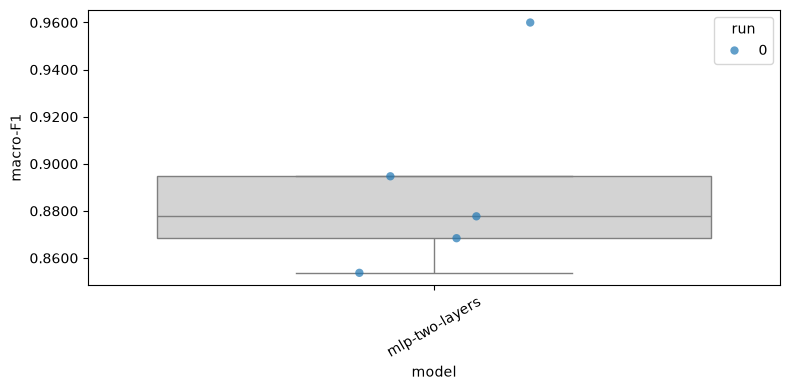

In [10]:
import pandas as pd

rows = []
for fold in range(num_folds):
    metrics_path = model_folder / f"fold-{fold}" / "metrics.json"
    with open(metrics_path, encoding="utf-8") as f:
        metrics = json.load(f)
    if metrics["model_args"] != model_args:
        raise ValueError(f"Configuration changed for {metrics_path}; rerun training.")
    rows.append({"model": model_name, "run": 0, "fold": fold,
                 "macro-F1": metrics["macro_f1"]})
comparison = pd.DataFrame(rows)
summary = comparison.groupby("model", sort=False)["macro-F1"].agg(["mean", "std", "count"])
print(summary.to_string())
part1.analysis.plot_box_and_points(comparison, metric="macro-F1")